# GaussianPlant: Structure-aligned Gaussian Splatting for 3D Reconstruction of Plants

**Yang Yang, Risa Shinoda, Hiroaki Santo, Fumio Okura** — [arXiv:2512.14087](https://arxiv.org/abs/2512.14087)

Reproduction of **Step 2 (structure extraction)** from the authors' release
[`Yrainy0615/GaussianPlant`](https://github.com/Yrainy0615/GaussianPlant) (commit `3c745e9c3c6b`), on **one scene
(`newplant9`)** from the authors' Google Drive dataset, followed by the authors'
branch **Chamfer-distance** evaluation against the released ground-truth branch cloud.

**Execution status / scope**

- **ADAPTED PYTHON DEMONSTRATION (要適合の実演)** — see the warning below.
- Single scene, one run; **not** a reproduction of paper-level dataset results.
- Runtime: **T4 GPU required** (the author pipeline hard-codes CUDA + gsplat).
  Expected total wall time ≈ 60–90 min (estimates; see section headers).

> ### ⚠️ Adaptation notice (EN)
> The released Drive dataset **does not contain** the pretrained *feature 3DGS* clouds
> (Step-1 output with 128-d DINOv3 semantic features) that Step 2 consumes. Producing
> them faithfully requires gated DINOv3 weights + the separate Feature-3DGS codebase
> trained ~30k iterations (the authors' issue tracker reports ~2 s/iter on an RTX 5090,
> i.e. ~16 h/scene) — infeasible in a Colab session. **Substitution used here:** a
> plain 3DGS cloud is pretrained **in this notebook** (3,000 iterations — sized for a
> free-tier T4 budget; see section 3) using the authors' own
> `GaussianModel`/renderer (COLMAP points3D init, L1+SSIM, densification) and padded
> with 128 zero semantic channels. The paper's semantic flow is therefore **inactive**;
> the branch/leaf init degrades to the authors' colour+geometry cues. All Step-2 code
> (structure extraction, binding, graph/MST, pruning, densification, evaluation) is the
> **authors' pinned code**, with three small documented compatibility adaptations:
> (1) removal of a stray unused `from turtle import speed` in `scene/__init__.py`
> (breaks headless runs); (2) a stub `pyvista` module on the import path (pyvista is
> only used by visualization functions not on this pipeline, but its import fails on
> Colab's IPython 7.34); (3) `numpy>=2` kept (Colab runtime) although the author README
> pins `<2` for their environment — `faiss-gpu-cu12` on this runtime is built against
> the numpy 2 ABI and all author modules were verified to import with numpy 2.
> The authors did not provide this Colab adaptation; validated behaviour is limited to
> what this notebook actually executes.
>
> ### ⚠️ 適合に関する注意（JP）
> 公開データセットには Step 2 の入力となる学習済み feature 3DGS 点群が含まれないため、
> 本ノートブック内で筆者らの `GaussianModel` を用いた通常 3DGS 前段学習で代用し、
> セマンティック特徴を 0 埋め 128 次元にパディングしています。論文のセマンティック
> フローは無効で、分岐/葉の初期化は色＋幾何の手掛かりに縮退します。Step 2 本体
> （構造抽出・評価コード）は筆者らの指定コミットのものを、3 点の小さな互換修正
> （未使用 `turtle` import の削除、未使用可視化関数のための `pyvista` スタブ、
> numpy>=2 の維持）を除き無修正で実行します。

## 0. Runtime selection / 実行環境の選択

**Select Runtime → Change runtime type → T4 GPU before running.**
This reproduction is GPU-only: the authors' `train.py` calls `torch.cuda.set_device`
and uses the gsplat CUDA rasterizer. **実行前に「ランタイムのタイプを変更」で
T4 GPU を選択してください。** The next cell fails loudly if no GPU is visible.

**Run all**: Runtime → Run all. Estimated (free-tier T4, from measured prior runs):
installs + JIT ~20–25 min, Drive download ~60–90 min (Drive rate limits),
3DGS pretrain (3k iters) ~10 min, Step-2 structure extraction (7k iters,
authors' flags) ~45–120 min, evaluation + plots ~5 min. These are estimates, not
measured guarantees.

In [ ]:
import torch
assert torch.cuda.is_available(), (
    "No GPU runtime detected. Select Runtime > Change runtime type > T4 GPU and rerun. "
    "GPU is required: the author pipeline uses the gsplat CUDA rasterizer.")
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | CUDA 13.0 | GPU: Tesla T4


## 1. Dependencies / 依存関係のインストール

Installs the authors' pinned `requirements.txt` **with the `numpy<2` line filtered out**,
plus `gsplat` (the authors' rendering backend), `faiss-gpu-cu12`, `ninja` and `gdown`.
**Deviation from the author README:** the README pins `numpy<2` for their conda env; on
this Colab runtime `faiss-gpu-cu12` is built against the numpy 2 ABI, and all author
modules were verified to import with numpy 2 — so we keep the Colab-preinstalled numpy
unchanged (replacing numpy underneath a live kernel corrupts the import state).
日本語: 筆者らの `requirements.txt` から `numpy<2` の行を除いてインストールし、gsplat・
faiss・gdown を入れます。本ランタイムでは faiss のため numpy 2 系を維持します
（README との差異；動作確認済み）。

In [ ]:
import subprocess, sys, time, urllib.request, numpy
print("preinstalled numpy:", numpy.__version__)
assert int(numpy.__version__.split(".")[0]) >= 2, "faiss-gpu-cu12 requires numpy>=2"
t0 = time.time()
req_url = "https://raw.githubusercontent.com/Yrainy0615/GaussianPlant/3c745e9c3c6b9947de9c9269239dbdf52da1085d/requirements.txt"
req_text = "\n".join(l for l in urllib.request.urlopen(req_url, timeout=60).read().decode().splitlines()
                     if l.strip() and not l.strip().startswith("numpy"))
open("/content/requirements_filtered.txt", "w").write(req_text)
for args in (["-r", "/content/requirements_filtered.txt"],
             ["gsplat", "faiss-gpu-cu12", "ninja", "gdown"]):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + args,
                       capture_output=True, text=True)
    print("pip", args[:1], "rc", r.returncode)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[-800:]); raise RuntimeError("pip install failed")
print("deps installed in %.1f min" % ((time.time() - t0) / 60))

preinstalled numpy: 2.1.3


pip ['-r'] rc 0


pip ['gsplat'] rc 0
deps installed in 0.6 min


### 1b. Get the authors' pinned code (inside Colab) / 筆者コードの取得

Blobless clone of the pinned commit **inside Colab** (`/content`, exists only for this
session). We build the `simple-knn` CUDA extension; the Feature-3DGS submodule (Step 1)
is intentionally **not** initialised. Asserts the checked-out commit matches the pin.
日本語: 指定コミットを Colab 内に取得し（blobless clone）、`simple-knn` のみビルドします。
Step 1 用の Feature-3DGS サブモジュールは初期化しません。

In [ ]:
%%bash
set -e
cd /content
if [ ! -d GaussianPlant ]; then
  git clone --filter=blob:none https://github.com/Yrainy0615/GaussianPlant.git GaussianPlant
fi
cd GaussianPlant
git fetch --filter=blob:none origin 3c745e9c3c6b9947de9c9269239dbdf52da1085d -q
git checkout -q 3c745e9c3c6b9947de9c9269239dbdf52da1085d
echo "HEAD: $(git rev-parse HEAD)"
test "$(git rev-parse HEAD)" = "3c745e9c3c6b9947de9c9269239dbdf52da1085d" || { echo "COMMIT MISMATCH"; exit 1; }
git submodule update -q --init submodules/simple-knn
pip install --no-build-isolation -q ./submodules/simple-knn
echo "simple-knn built"

HEAD: 3c745e9c3c6b9947de9c9269239dbdf52da1085d
simple-knn built


Cloning into 'GaussianPlant'...
Updating files: 100% (86/86), done.


### 1c. Compatibility shims + scientific stack check / 互換修正と環境確認

**(1)** Removes the authors' stray, unused `from turtle import speed` line from
`scene/__init__.py` (it pulls Tk and crashes headless runtimes; `train.py` imports this
module). **(1b)** Adds `weights_only=False` to the two `torch.load` calls in
`scene/__init__.py` — torch ≥ 2.6 flipped the default to `True`, which rejects the
authors' PCA/text-feature checkpoints (`utils.visualization.TorchPCA`); these files
ship inside the pinned author repository, so they are trusted pinned content.
**(2)** Installs a stub `pyvista` module at `/content/shims` (prepended to
`sys.path` and `PYTHONPATH`): pyvista is imported at module level by the authors'
`utils/gs_utils.py` but only used by visualization functions not on this pipeline;
its import fails because Colab's IPython 7.34 lacks `IPython.core.guarded_eval`.
**(3)** Verifies the author import chain, then triggers gsplat's JIT CUDA build
(measured 794 s ≈ 13 min on the first run of a fresh T4 runtime) with a tiny dummy
rasterization so later cells are quiet.
日本語: 未使用の `turtle` import を削除し、torch 2.6+ の `weights_only` 既定値変更に
対処し（`scene/__init__.py` の 2 箇所の `torch.load` に `weights_only=False`）、
未使用の pyvista をスタブで置き換え、筆者コードの import 経路を検証した上で、
gsplat の CUDA カーネルを事前ビルドします（初回は約13分）。

In [ ]:
import os, sys, time, subprocess, torch

# numpy sanity: the process-wide numpy must match what pip has on disk
import numpy as np, importlib.metadata as im
if np.__version__ != im.version("numpy"):
    raise RuntimeError(
        f"numpy mismatch: kernel has {np.__version__}, disk has {im.version('numpy')}. "
        "Runtime > Restart session, then Run all again (installs are idempotent).")

# (1) documented 1-line author-code fix
REPO_DIR = "/content/GaussianPlant"
sys.path.insert(0, "/content/shims")          # (2) pyvista stub shadows the real pkg
sys.path.insert(1, REPO_DIR)
init_py = os.path.join(REPO_DIR, "scene", "__init__.py")
src = open(init_py).read()
if "from turtle import speed" in src:
    src = src.replace("from turtle import speed\n", "")
    print("applied documented fix: removed stray 'from turtle import speed'")
# (1b) torch>=2.6 defaults weights_only=True; the authors' torch.load calls predate
# that. The checkpoints ship inside the pinned author repo, so non-weight tensors
# (TorchPCA object, dict) are trusted pinned-repo content -> weights_only=False.
n_patch = 0
if "weights_only" not in src:
    for old in ("torch.load(pca_path, map_location='cpu')",
                "torch.load(tf_path, map_location='cpu')"):
        if old in src:
            src = src.replace(old, old[:-1] + ", weights_only=False)")
            n_patch += 1
    open(init_py, "w").write(src)
    print(f"applied documented fix: weights_only=False on {n_patch} torch.load calls in scene/__init__.py")

# (2) stub pyvista module (only unused viz functions need the real one)
os.makedirs("/content/shims", exist_ok=True)
open("/content/shims/pyvista.py", "w").write(
    '"""Stub: the real pyvista is not importable on Colab IPython 7.34\n'
    '(missing IPython.core.guarded_eval). Only unused visualization helpers\n'
    'of the author code reference it; annotations like pv.PolyData resolve\n'
    'to a permissive stub."""\n'
    'class _Stub:\n'
    '    def __init__(self, *a, **k): raise RuntimeError(\n'
    '        "pyvista stub: real pyvista not importable on this runtime")\n'
    'def __getattr__(name):\n'
    '    return _Stub\n')
os.environ["PYTHONPATH"] = "/content/shims"

# (3) author import chain + simple-knn
from simple_knn._C import distCUDA2
print("simple-knn OK", distCUDA2(torch.randn(10, 3).cuda()).shape)
import scene.gaussian_model, scene.dataset_readers, gaussian_renderer, arguments
print("author import chain OK")

# (3b) gsplat JIT build
import gsplat
print("gsplat", gsplat.__version__)
t0 = time.time()
out, _, _ = gsplat.rasterization(
    torch.randn(1000, 3, device="cuda"),
    torch.nn.functional.normalize(torch.randn(1000, 4, device="cuda"), dim=-1),
    torch.rand(1000, 3, device="cuda") * 0.01,
    torch.rand(1000, device="cuda"),
    torch.rand(1000, 3, device="cuda"),
    torch.eye(4, device="cuda")[None],
    torch.tensor([[[100., 0, 50], [0, 100., 50], [0, 0, 1]]], device="cuda"),
    100, 100)
torch.cuda.synchronize()
print("gsplat JIT build + rasterize OK in %.1f s" % (time.time() - t0), tuple(out.shape))

(    ● ) gsplat: Setting up CUDA with MAX_JOBS=10 (This may take a few minutes the first time)

gsplat: CUDA extension has been set up successfully in 655.76 seconds.

gsplat JIT build + rasterize OK in 656.2 s (1, 100, 100, 3)


## 2. Dataset: scene `newplant9` / データセットの取得

Downloads **only** the files needed for this pipeline from the `newplant9` folder of the
authors' Drive [gaussianplant folder](https://drive.google.com/drive/folders/12X6jU1ZrLO_QvD8X5ACeypJwc4HZQQrV)
(scene id `1nW1g93FsqHua-k6QbqvKqRt8k9h9DZuH`): `sparse/0` (COLMAP), the registered `images/`, the
per-view plant masks in `masks/`, and the two ground-truth clouds `point_cloud_branch.ply`
/ `point_cloud_leaf.ply` (evaluation only; per the authors' issue #5,
`point_cloud_branch.ply` is the GT dense branch cloud). Files are fetched one by one
(the Drive folder has >50 files per subfolder, beyond `gdown --folder`'s limit) with
skip-if-exists resume and bounded retries; the large `*_leaves` leaf-instance folders are
skipped (not used by this reproduction). 日本語: 筆者らの Drive から newplant9 の
必要ファイルのみ（COLMAP sparse・登録画像・マスク・評価用 GT 点群）を 1 ファイルずつ
取得します（`*_leaves` フォルダは本再現では不使用のためスキップ）。

**Adaptation (documented):** Google Drive permanently refuses a few registered
files ("too many accesses" quota, observed: IMG_1429.JPG, IMG_1440.JPG in one
session; different files in another), and the authors' `readColmapCameras`
opens every image listed in `images.bin` unconditionally, so a missing file
would crash the loader. After downloading, this cell therefore builds
`/content/gaussianplant_data/newplant9_f`: a copy of the scene where every file
is a symlink except `sparse/0/images.bin`, which is **rewritten** (same COLMAP
binary format, values parsed with the authors' own `colmap_loader.py`) to
reference only images actually on disk. Author code then runs unmodified on the
copy. 修正点: Drive が配布を拒否した少数の登録画像があるため、`images.bin` のみを
実在画像のみを参照するよう書き直したフィルタ済みシーンコピーを作成します（他は
すべてシンボリックリンク）。

In [ ]:
import re, os, sys, time, subprocess, urllib.request

FOLDER = "1nW1g93FsqHua-k6QbqvKqRt8k9h9DZuH"
ROOT = "/content/gaussianplant_data/newplant9"

def list_folder(fid):
    html = urllib.request.urlopen(
        f"https://drive.google.com/embeddedfolderview?id={fid}", timeout=60).read().decode()
    out = []
    for m in re.finditer(
            r'<div class="flip-entry" id="entry-([\w-]+)"[^>]*>.*?'
            r'href="https://drive\.google\.com/(file/d/|drive/folders/)([\w-]+).*?'
            r'flip-entry-title">([^<]+)</div>', html, re.S):
        out.append(("folder" if m.group(2) == "drive/folders/" else "file",
                    m.group(3), m.group(4)))
    return out

def download(fid, path, failed):
    """Download one Drive file; record persistent failures instead of aborting
    the whole cell (Drive rate limits are transient and the cell is resumable)."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return 0
    last = ""
    for attempt in range(6):
        r = subprocess.run([sys.executable, "-m", "gdown", fid, "-O", path],
                           capture_output=True, text=True)
        if r.returncode == 0 and os.path.exists(path) and os.path.getsize(path) > 0:
            time.sleep(0.7)   # gentle throttle for Drive rate limits
            return 1
        if os.path.exists(path):
            os.remove(path)
        last = (r.stdout + r.stderr)[-300:]
        time.sleep(min(60 * (attempt + 1), 300))   # strong backoff: Drive throttles bursts
    failed.append((fid, path, last))
    print("WARN: giving up on", os.path.basename(path), flush=True)
    return 0

FAILED = []

t0 = time.time(); n = [0]
def show():
    if n[0] and n[0] % 50 == 0:
        print(n[0], "files downloaded %.1f min" % ((time.time() - t0) / 60), flush=True)

def dl_dir(fid, dest, only_names=None, top_files_only=False):
    os.makedirs(dest, exist_ok=True)
    for kind, eid, name in list_folder(fid):
        if "_leaves" in name or (top_files_only and kind == "folder"):
            continue   # *_leaves GT instance folders & mask subfolders are not used
        if kind == "folder":
            dl_dir(eid, os.path.join(dest, name))
        elif only_names is None or name in only_names:
            n[0] += download(eid, os.path.join(dest, name), FAILED); show()

entries = {name: (kind, eid) for kind, eid, name in list_folder(FOLDER)}
# 1) COLMAP sparse first, then the two ground-truth clouds
sparse_id = entries["sparse"][1]
sparse0 = [eid for kind, eid, name in list_folder(sparse_id) if name == "0"][0]
dl_dir(sparse0, os.path.join(ROOT, "sparse", "0"))
for ply in ("point_cloud_branch.ply", "point_cloud_leaf.ply"):
    kind, eid = entries[ply]
    if kind == "file":
        n[0] += download(eid, os.path.join(ROOT, ply), FAILED); show()

# 2) registered image names from the authors' pinned colmap_loader (numpy only)
import importlib.util
spec = importlib.util.spec_from_file_location("colmap_loader", "/content/GaussianPlant/scene/colmap_loader.py")
cl = importlib.util.module_from_spec(spec); spec.loader.exec_module(cl)
import struct
extr = cl.read_extrinsics_binary(os.path.join(ROOT, "sparse", "0", "images.bin"))
reg = {e.name for e in extr.values()}
print("registered images:", len(reg))

# 3) masks BEFORE images: every camera needs its mask, so a rate-limit pause late
#    in the image list must not leave us with images but no masks
img_id = entries["images"][1]; msk_id = entries["masks"][1]
masks_top = [(eid, name) for kind, eid, name in list_folder(msk_id) if kind == "file"]
os.makedirs(os.path.join(ROOT, "masks"), exist_ok=True)
for eid, name in masks_top:
    if name in reg:
        n[0] += download(eid, os.path.join(ROOT, "masks", name), FAILED); show()
dl_dir(img_id, os.path.join(ROOT, "images"), only_names=reg)

print("downloaded", n[0], "new files in %.1f min" % ((time.time() - t0) / 60))
for entry in sorted(os.listdir(ROOT)):
    p = os.path.join(ROOT, entry)
    print(("dir " if os.path.isdir(p) else "file"), entry,
          "" if os.path.isdir(p) else f"{os.path.getsize(p)//1024} KiB")
n_imgs = len([f for f in os.listdir(os.path.join(ROOT, "images")) if f in reg])
n_msks = len([f for f in os.listdir(os.path.join(ROOT, "masks")) if f in reg])
print("registered images on disk:", n_imgs, "| registered masks on disk:", n_msks,
      "| sparse/0:", sorted(os.listdir(os.path.join(ROOT, "sparse", "0"))))
if FAILED:
    print(f"{len(FAILED)} files failed after retries:")
    for fid, path, err in FAILED:
        print("  -", os.path.basename(path))
# honest guard: the authors' loader skips images whose mask is missing, so a few
# unpaired files are tolerable (62/63 observed); proceed with >= 40 usable pairs
if n_msks < 40:
    raise RuntimeError(
        f"Insufficient paired data: {n_imgs} registered images, {n_msks} masks on disk "
        f"(need >=40 usable pairs). Persistent failures: {len(FAILED)}. "
        "Re-run the cell (resume skips already-downloaded files).")
if n_imgs != n_msks:
    print(f"note: {abs(n_imgs - n_msks)} registered file(s) missing; "
          "the authors' loader will skip those cameras")

# 4) filtered scene copy for the authors' loader: Drive permanently refuses a few
#    registered files ("too many accesses" quota), but `readColmapCameras` opens
#    every image listed in images.bin unconditionally and would crash. We rewrite
#    ONLY images.bin to reference images actually on disk (documented adaptation;
#    same COLMAP binary format, parsed/written via the authors' own loader values)
#    and symlink everything else, so author code runs unmodified on the copy.
FILT = "/content/gaussianplant_data/newplant9_f"
for root, dirs, files in os.walk(ROOT):
    rel = os.path.relpath(root, ROOT)
    os.makedirs(FILT if rel == "." else os.path.join(FILT, rel), exist_ok=True)
    for f in files:
        dst = os.path.join(FILT, rel, f)
        if rel == os.path.join("sparse", "0") and f == "images.bin":
            continue   # rewritten below
        if not os.path.exists(dst):
            os.symlink(os.path.abspath(os.path.join(root, f)), dst)
on_disk = set(os.listdir(os.path.join(ROOT, "images")))
kept = {i: e for i, e in extr.items() if e.name in on_disk}
with open(os.path.join(FILT, "sparse", "0", "images.bin"), "wb") as w:
    w.write(struct.pack("<Q", len(kept)))
    for i in sorted(kept):
        e = kept[i]
        w.write(struct.pack("<idddddddi", e.id, *e.qvec, *e.tvec, e.camera_id))
        w.write(e.name.encode() + b"\x00")
        w.write(struct.pack("<Q", len(e.xys)))
        for (x, y), pid in zip(e.xys, e.point3D_ids):
            w.write(struct.pack("<ddq", float(x), float(y), int(pid)))
chk = cl.read_extrinsics_binary(os.path.join(FILT, "sparse", "0", "images.bin"))
assert {e.name for e in chk.values()} == on_disk & reg, "images.bin rewrite mismatch"
print(f"filtered scene ready: {len(kept)}/{len(extr)} registered cameras in {FILT}")

registered images: 63


50 files downloaded 2.5 min


WARN: giving up on IMG_1441.JPG


100 files downloaded 32.7 min


WARN: giving up on IMG_1426.JPG


downloaded 131 new files in 61.9 min
dir  images 
dir  masks 
file point_cloud_branch.ply 8593 KiB
file point_cloud_leaf.ply 42545 KiB
dir  sparse 
registered images on disk: 62 | registered masks on disk: 62 | sparse/0: ['cameras.bin', 'depth_params.json', 'images.bin', 'points3D.bin', 'points3D.ply']
2 files failed after retries:
  - IMG_1441.JPG
  - IMG_1426.JPG


filtered scene ready: 62/63 registered cameras in /content/gaussianplant_data/newplant9_f


### 2b. Input preview: image + plant mask overlay / 入力プレビュー

Shows one captured view with the authors' plant mask overlaid in red — this mask is used
by the authors' built-in `--rm_bg` route to build the plant-only point cloud. Also
validates the GT branch cloud (point count, extent) with `plyfile`. 日本語:
撮影画像 1 枚に筆者らの植物マスク（赤）を重ねて表示します。このマスクは後段の
`--rm_bg` で植物点群のみを抽出するために使われます。GT 枝点群も読み込んで検証します。
(表示上の注意: 筆者コードの import が matplotlib Agg バックエンドを強制するため、
本ノートブックの図は savefig + IPython.display で出力します。)

images: 62 | paired image+mask: 61


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))


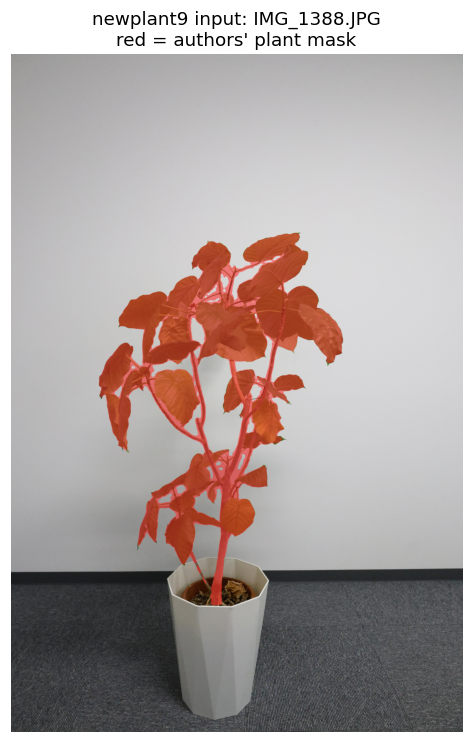

GT point_cloud_branch.ply: 11512 points | extent: [-1.691 -1.656 -1.029] [0.775 3.516 1.823]


In [ ]:
import glob, os, numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from plyfile import PlyData

SCENE = "/content/gaussianplant_data/newplant9"
imglist = sorted(glob.glob(os.path.join(SCENE, "images", "*")))
masknames = {os.path.basename(p) for p in glob.glob(os.path.join(SCENE, "masks", "*.JPG"))}
paired = [p for p in imglist if os.path.basename(p) in masknames]
print("images:", len(imglist), "| paired image+mask:", len(paired))
if not paired:
    raise RuntimeError("No image+mask pair on disk; re-run the download cell first.")
img = Image.open(paired[0]); msk = Image.open(
    os.path.join(SCENE, "masks", os.path.basename(paired[0]))).resize(img.size)
overlay = np.array(img.convert("RGB"))
m = np.array(msk.convert("L")) > 128
overlay[m] = (0.45 * overlay[m] + 0.55 * np.array([255, 40, 40])).astype(np.uint8)
fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(overlay)
ax.set_title(f"newplant9 input: {os.path.basename(paired[0])}\nred = authors' plant mask")
ax.axis("off")
# The authors' gs_utils.py calls matplotlib.use('Agg') at import time (reached via the
# author import chain above), which silences inline figure display. Documented output
# adaptation: render with Agg, save the PNG, and display it via IPython.display so the
# figure is captured as a durable notebook output.
from IPython.display import Image as IPyImage, display
fig.savefig("/content/preview_input_mask.png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(IPyImage(filename="/content/preview_input_mask.png"))

gt = PlyData.read(os.path.join(SCENE, "point_cloud_branch.ply"))
v = gt["vertex"].data
pts = np.stack([v["x"], v["y"], v["z"]], 1)
print("GT point_cloud_branch.ply:", pts.shape[0], "points | extent:",
      np.round(pts.min(0), 3), np.round(pts.max(0), 3))

### 2c. Parse the COLMAP scene with the authors' loader / COLMAP シーンの解析

Uses the authors' `readColmapSceneInfo` (pinned code) on the **filtered scene
copy** (`newplant9_f`, see the download cell) with `features=""` and `depths=""`
— the semantic feature maps and depths the loader would normally read are not
part of the released scene, so `CameraInfo.semantic_feature` is `None` (handled
gracefully by the pinned loader). 日本語: 筆者らのローダでフィルタ済みシーン
コピーを読み込みます。セマンティック特徴マップとデプスは提供されていないため
`None` として扱われます。

In [ ]:
from scene.dataset_readers import readColmapSceneInfo
scene_info = readColmapSceneInfo("/content/gaussianplant_data/newplant9_f", images="images", depths="", masks="masks",
                                 features="", eval=False, train_test_exp=False)
print("cameras:", len(scene_info.train_cameras), "| sparse points:",
      scene_info.point_cloud.points.shape[0], "| semantic_feature_dim:",
      scene_info.semantic_feature_dim, "| extent radius: %.3f" % scene_info.nerf_normalization["radius"])

Reading camera 1/62

Reading camera 2/62

Reading camera 3/62

Reading camera 4/62

Reading camera 5/62

...

Reading camera 59/62

Reading camera 60/62

Reading camera 61/62

Reading camera 62/62


cameras: 61 | sparse points: 38469 | semantic_feature_dim: None | extent radius: 7.786


## 3. Substituted Step-1: plain 3DGS pretraining / 前段 3DGS 学習（代用）

**Adapted stage.** Trains a plain 3D Gaussian Splatting cloud for **3,000 iterations**
with the authors' own `GaussianModel`, `create_from_pcd` (COLMAP points3D + RGB,
simple-knn scales) and gsplat renderer; loss = 0.8·L1 + 0.2·(1−SSIM) (the authors' loss
form), with standard clone/split densification (adaptive gradient quantile, as the
authors do for gsplat gradients) and the authors' 1,000-iteration opacity-reset
interval. This replaces the paper's DINOv3 feature-3DGS pretraining (infeasible here —
see the top warning). **Why 3,000 iterations:** Step 2's per-iteration cost scales with
the number of AppGS (each AppGS is paired with its nearest StrPr every iteration), and
a 7k-iteration cloud (~2.05M points) made the authors' 7k-iteration Step 2 exceed a
practical free-tier T4 session by a wide margin (measured >4.3 h without completing).
A 3k-iteration cloud (~0.4M points) keeps the authors' Step-2 flags and 7,000
iterations intact while fitting the budget. One further documented tweak: the opacity
reset scheduled exactly on the final iteration is skipped, so the exported cloud keeps
converged opacities (at 7k the last reset was at 6,000, with 1,000 iterations to
recover). Images are used at resolution factor 4 (~1008 px). 日本語: 筆者らの
`GaussianModel` をそのまま使い、通常の 3DGS を **3,000 反復**学習して Step 2 の入力点群の
代用とします（論文の DINOv3 feature-3DGS の代用）。Step 2 の反復毎コストは点群規模に
比例するため、T4 の実行時間枠に収めるよう 3,000 反復としています（Step 2 側のフラグは
筆者コードのまま変更なし）。最終反復の不透明度リセットのみ、収束した値を書き出すため
スキップします（文書化済みの修正）。

In [ ]:
import random, time
import torch
from argparse import Namespace
import argparse
from scene.gaussian_model import GaussianModel
from utils.camera_utils import cameraList_from_camInfos
from gaussian_renderer import render
from utils.loss_utils import l1_loss, ssim
from arguments import OptimizationParams

DEVICE = torch.device("cuda")
# the authors' ParamGroup requires a real ArgumentParser to register defaults
opt = OptimizationParams(argparse.ArgumentParser()); opt.iterations = 3000
pipe = Namespace(convert_SHs_python=False, compute_cov3D_python=False)
cam_args = Namespace(resolution=4, data_device="cpu", train_test_exp=False)
cameras = cameraList_from_camInfos(scene_info.train_cameras, 1.0, cam_args, False, False)
extent = scene_info.nerf_normalization["radius"]
print("cameras:", len(cameras), "| render res:", cameras[0].image_width, "x", cameras[0].image_height)

gaussians = GaussianModel(3, DEVICE, "/content/pretrain")
gaussians.create_from_pcd(scene_info.point_cloud, extent, 128, speedup=True)
# the authors' train.py calls training_setup(opt) right after loading/creating the
# model; without it gaussians.optimizer is None (verified by smoke probe)
gaussians.training_setup(opt)

bg = torch.zeros(3, device=DEVICE)
viewpoint_stack = cameras.copy()
t0 = time.time()
for iteration in range(1, opt.iterations + 1):
    gaussians.update_learning_rate(iteration)
    if not viewpoint_stack:
        viewpoint_stack = cameras.copy()
    cam = viewpoint_stack.pop(random.randint(0, len(viewpoint_stack) - 1))
    pkg = render(cam, gaussians, pipe, bg)
    image = pkg["render"]
    gt_image = cam.original_image.to(DEVICE)
    Ll1 = l1_loss(image, gt_image)
    loss = (1.0 - opt.lambda_dssim) * Ll1 + opt.lambda_dssim * (1.0 - ssim(image, gt_image))
    loss.backward()
    with torch.no_grad():
        if iteration < opt.densify_until_iter:
            vis = pkg["visibility_filter"]
            gaussians.max_radii2D[vis] = torch.max(gaussians.max_radii2D[vis], pkg["radii"][vis])
            gaussians.add_densification_stats(pkg["viewspace_points"], vis)
            if iteration > opt.densify_from_iter and iteration % opt.densification_interval == 0:
                gg = (gaussians.xyz_gradient_accum / gaussians.denom.clamp_min(1)).norm(dim=-1)
                thr = torch.quantile(gg[gg > 0], 0.9).item() if (gg > 0).any() else 1e9
                gaussians.densify_and_prune(thr, 0.005, extent, 400, pkg["radii"])
            # documented tweak: skip the reset scheduled on the FINAL iteration so the
            # exported cloud keeps converged opacities (author interval otherwise kept)
            if iteration % opt.opacity_reset_interval == 0 and iteration < opt.iterations:
                gaussians.reset_opacity()
        if iteration < opt.iterations:
            gaussians.optimizer.step(); gaussians.optimizer.zero_grad(set_to_none=True)
        if iteration % 500 == 0 or iteration == 1:
            print(f"iter {iteration:5d} | loss {loss.item():.4f} | pts {gaussians.get_xyz.shape[0]} "
                  f"| {iteration / (time.time() - t0):.1f} it/s", flush=True)
print("pretrain done in %.1f min" % ((time.time() - t0) / 60))

cameras: 61 | render res: 1001 x 1504
Number of points at initialisation :  38469


iter     1 | loss 0.3627 | pts 38469 | 0.8 it/s


iter   500 | loss 0.0772 | pts 38469 | 9.9 it/s


Pruning 0 large vs points out of 42316 total points.
Pruning 66 large ws points out of 42316 total points.


Pruning 0 large vs points out of 46415 total points.
Pruning 21 large ws points out of 46415 total points.


...

Pruning 0 large vs points out of 284764 total points.
Pruning 25 large ws points out of 284764 total points.


Pruning 0 large vs points out of 312884 total points.
Pruning 20 large ws points out of 312884 total points.


Pruning 0 large vs points out of 343874 total points.
Pruning 25 large ws points out of 343874 total points.


Pruning 0 large vs points out of 377945 total points.
Pruning 16 large ws points out of 377945 total points.
iter  3000 | loss 0.0412 | pts 377651 | 7.4 it/s


pretrain done in 6.8 min


### 3b. Export the substitute pretrain cloud / 代用点群の書き出し

Writes the pretrained cloud with the authors' `save_ply` (it serialises 128 semantic
channels; ours are zeros) to the exact Step-2 layout the pinned loader expects —
`newplant9_f/feature_pretrain/point_cloud/iteration_30000/point_cloud.ply` inside the
filtered scene that Step 2 reads — and verifies the produced PLY header.
日本語: 筆者らの `save_ply` で、Step 2（フィルタ済みシーン）が期待する配置
`newplant9_f/feature_pretrain/point_cloud/iteration_30000/point_cloud.ply` に保存し、
PLY ヘッダを検証します（セマンティック 128 チャンネルは 0）。

In [ ]:
import os
from plyfile import PlyData
PRETRAIN_PLY = os.path.join("/content/gaussianplant_data/newplant9_f", "feature_pretrain", "point_cloud", "iteration_30000", "point_cloud.ply")
os.makedirs(os.path.dirname(PRETRAIN_PLY), exist_ok=True)
gaussians.save_ply(PRETRAIN_PLY)
names = PlyData.read(PRETRAIN_PLY)["vertex"].data.dtype.names
print("saved:", PRETRAIN_PLY, "|", os.path.getsize(PRETRAIN_PLY) // 2**20, "MiB")
print("semantic channels:", sum(n.startswith("semantic_") for n in names),
      "| f_rest:", sum(n.startswith("f_rest") for n in names),
      "| label:", "label_0" in names)

saved: /content/gaussianplant_data/newplant9_f/feature_pretrain/point_cloud/iteration_30000/point_cloud.ply | 275 MiB
semantic channels: 128 | f_rest: 45 | label: True


### 3c. Preview the pretrained cloud / 点群プレビュー

Colour scatter of the pretrained cloud from two static views (PNG output kept as durable
evidence; no interactive widget). 日本語: 学習した点群を 2 視点からカラー散布図で
表示します。

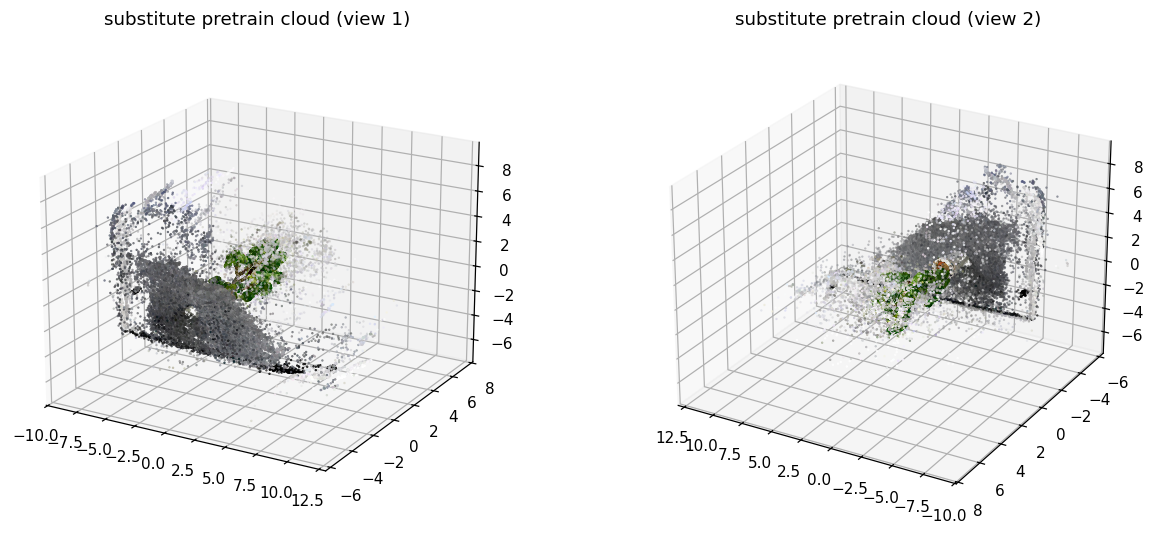

In [ ]:
import matplotlib.pyplot as plt
xyz = gaussians.get_xyz.detach().cpu().numpy()
col = (0.2820948 * gaussians.get_features[:, 0].detach().cpu().numpy() + 0.5).clip(0, 1)
fig = plt.figure(figsize=(12, 5))
for i, (el, az) in enumerate([(20, -60), (25, 120)]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    ax.scatter(xyz[::4, 0], xyz[::4, 1], xyz[::4, 2], s=0.3, c=col[::4])
    ax.view_init(el, az); ax.set_title(f"substitute pretrain cloud (view {i+1})")
plt.tight_layout()
# Agg is forced by the authors' gs_utils import (see the input-preview cell):
# save + IPython.display instead of plt.show() so the PNG is a durable output.
from IPython.display import Image as IPyImage, display
fig.savefig("/content/preview_pretrain_cloud.png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(IPyImage(filename="/content/preview_pretrain_cloud.png"))

## 4. Step 2 — authors' structure extraction, unmodified / Step 2（筆者コードを無修正で実行）

Runs the authors' `train.py` with the flags documented in the pinned README's Step-2
section (auto branch fraction, cluster_size 40, binding + axis + graph regularisers,
isolation pruning, branch densification, **7,000 iterations** — the authors'
documented Step-2 value), plus the documented
`--load_iteration 30000 --rm_bg` route so the plant-only cloud is built from the
released 2D masks on the fly. `-r 4` matches the pretraining resolution;
`--data_device cpu` keeps the ~190 images in host RAM. `PYTHONPATH` points at the
documented pyvista stub. `--source_path` is the filtered scene copy (`newplant9_f`,
see the download cell). Full log at `/content/step2_train.log`; the cell shows the tail.
日本語: 筆者らの README 記載のコマンド（パラメータは同様）を `--rm_bg` 経路で実行します。

In [ ]:
%%bash
set -o pipefail
cd /content/GaussianPlant
export CUDA_HOME=/usr/local/cuda
export PYTHONPATH=/content/shims
time python train.py \
  --source_path /content/gaussianplant_data/newplant9_f \
  --root_path   /content/gaussianplant_data \
  --model_path  /content/output/newplant9/run \
  --label_init joint --branch_frac -1 --cluster_size 40 \
  --reg_bind \
  --reg_axis  --lambda_axis 1.0 \
  --reg_graph --graph_from 1000 --graph_interval 50 \
  --prune_isolated --prune_from 1500 --prune_interval 500 --prune_until 4000 \
  --densify_branch --branch_split_ratio 1.5 --max_strpr_num 4000 \
  --label_lr 0 --iterations 7000 --disable_viewer \
  --load_iteration 30000 --rm_bg \
  -r 4 --data_device cpu 2>&1 | tee /content/step2_train.log | grep -v "Training progress" | tail -45

[ITER 2000] split 68 under-covering branch StrPr (now 3493 StrPr) [25/10 16:37:10]

[ITER 2500] pruned 52 isolated branch StrPr -> leaf [25/10 16:42:42]

[ITER 2500] split 53 under-covering branch StrPr (now 3546 StrPr) [25/10 16:42:42]

[ITER 3000] Saving Gaussians [25/10 16:48:15]

[ITER 3000] pruned 44 isolated branch StrPr -> leaf [25/10 16:48:30]

[ITER 3000] split 43 under-covering branch StrPr (now 3589 StrPr) [25/10 16:48:30]

[ITER 3500] pruned 25 isolated branch StrPr -> leaf [25/10 16:54:12]

[ITER 3500] pruned 2 oversized StrPr (> 20% scene extent), now 3587 [25/10 16:54:12]

[ITER 3500] split 41 under-covering branch StrPr (now 3628 StrPr) [25/10 16:54:12]

[ITER 4000] pruned 17 isolated branch StrPr -> leaf [25/10 16:59:53]

[ITER 4000] pruned 2 oversized StrPr (> 20% scene extent), now 3626 [25/10 16:59:53]

[ITER 4000] split 33 under-covering branch StrPr (now 3659 StrPr) [25/10 16:59:54]

[ITER 4500] pruned 6 oversized StrPr (> 20% scene extent), now 3653 [25/10 17:05:


real	78m0.176s
user	75m17.852s
sys	3m12.339s


## 5. Evaluation: branch Chamfer distance / 評価

Runs the authors' `eval_chamfer.py` unmodified: symmetric Chamfer distance (L2 and
squared, pytorch3d convention) between the recovered branch points (`branch.ply`,
bounded AppGS bound to branch StrPrs) and the released GT dense branch cloud
`point_cloud_branch.ply`. Coordinates are in metres (the paper reports mm — compare
magnitudes carefully). 日本語: 筆者らの評価スクリプトで、復元した枝点群と GT 枝点群の
Chamfer 距離を計測します（座標はメートル単位）。

In [ ]:
%%bash
set -o pipefail
cd /content/GaussianPlant
python eval_chamfer.py \
  --gt /content/gaussianplant_data/newplant9/point_cloud_branch.ply \
  --points /content/output/newplant9/run/point_cloud/iteration_7000/branch.ply \
  --cylinder /content/output/newplant9/run/point_cloud/iteration_7000/strpr_branch.ply

[Open3D WARNING] geometry::TriangleMesh appears to be a geometry::PointCloud (only contains vertices, but no triangles).
GT: /content/gaussianplant_data/newplant9/point_cloud_branch.ply  n_gt=11512
[Open3D WARNING] geometry::TriangleMesh appears to be a geometry::PointCloud (only contains vertices, but no triangles).
[cylinder] /content/output/newplant9/run/point_cloud/iteration_7000/strpr_branch.ply
  CD(L2)=0.218769  (pred->gt 0.079540, gt->pred 0.139229)  CD(sq)=7.708628e-02  n_pred=523
[Open3D WARNING] geometry::TriangleMesh appears to be a geometry::PointCloud (only contains vertices, but no triangles).
[points]   /content/output/newplant9/run/point_cloud/iteration_7000/branch.ply
  CD(L2)=0.160945  (pred->gt 0.046200, gt->pred 0.114745)  CD(sq)=4.971559e-02  n_pred=11157


### 5b. GT vs prediction visual comparison / GT と予測の可視化

Static 3D scatter (PNG) comparing the released GT branch cloud (grey — the authors'
reference annotation) against this run's predicted branch points (red) and the extracted
MST skeleton (blue). Left: reference only; right: overlay. 日本語: GT の枝点群（グレー）と
本実行の予測枝点群（赤）、抽出された MST スケルトン（青）を重ねて表示します。

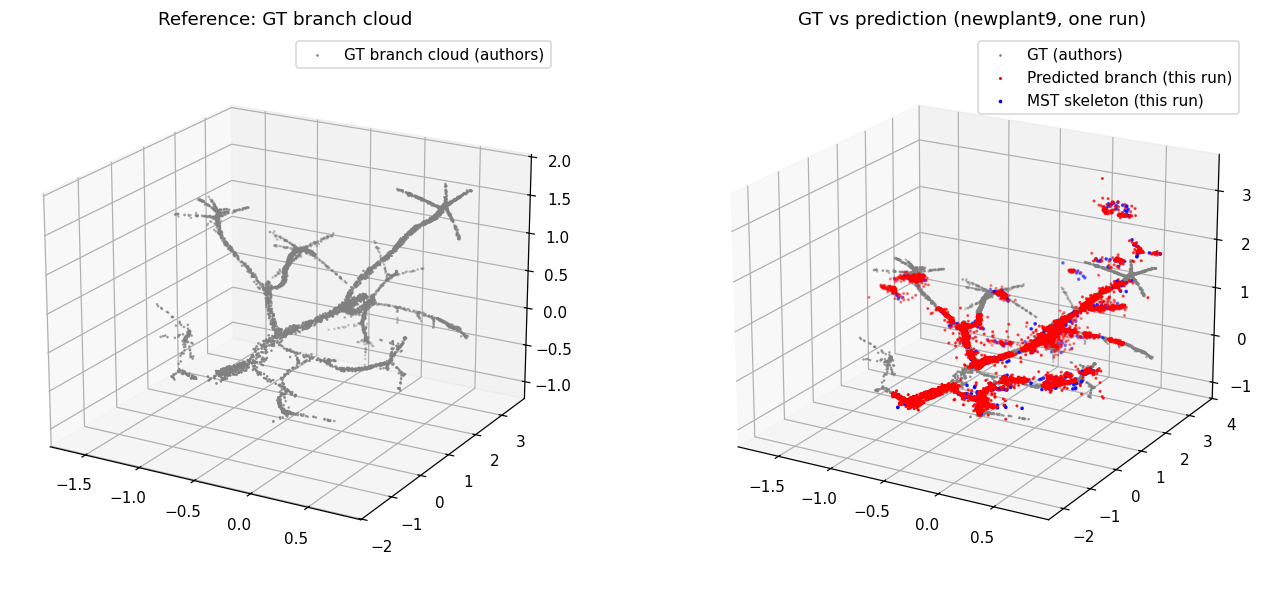

n_gt: 11512 n_pred: 11157


In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
from plyfile import PlyData

def load_xyz(p):
    v = PlyData.read(p)["vertex"].data
    return np.stack([v["x"], v["y"], v["z"]], 1)

gt = load_xyz(os.path.join(SCENE, "point_cloud_branch.ply"))
pred = load_xyz("/content/output/newplant9/run/point_cloud/iteration_7000/branch.ply")
try:
    mst = load_xyz("/content/output/newplant9/run/point_cloud/iteration_7000/mst.ply")
except Exception:
    mst = None
fig = plt.figure(figsize=(13, 5.5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(gt[::2, 0], gt[::2, 1], gt[::2, 2], s=0.5, c="grey", label="GT branch cloud (authors)")
ax.view_init(20, -60); ax.set_title("Reference: GT branch cloud"); ax.legend()
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(gt[::2, 0], gt[::2, 1], gt[::2, 2], s=0.5, c="grey", label="GT (authors)")
ax2.scatter(pred[:, 0], pred[:, 1], pred[:, 2], s=1.0, c="red", label="Predicted branch (this run)")
if mst is not None:
    ax2.scatter(mst[:, 0], mst[:, 1], mst[:, 2], s=2.0, c="blue", label="MST skeleton (this run)")
ax2.view_init(20, -60); ax2.set_title("GT vs prediction (newplant9, one run)"); ax2.legend()
plt.tight_layout()
# Agg is forced by the authors' gs_utils import (see the input-preview cell):
# save + IPython.display instead of plt.show() so the PNG is a durable output.
from IPython.display import Image as IPyImage, display
fig.savefig("/content/gt_vs_prediction.png", dpi=110, bbox_inches="tight")
plt.close(fig)
display(IPyImage(filename="/content/gt_vs_prediction.png"))
print("n_gt:", len(gt), "n_pred:", len(pred))

### 5c. Results export / 結果の表出力

Recomputes the Chamfer metrics with the authors' own function and exports one CSV row
with the run's key numbers (inside Colab). 日本語: 筆者らの chamfer 関数で再計算し、
主要な結果数値を CSV として Colab 内に保存します。

In [ ]:
import csv, json, sys
sys.path.insert(0, "/content/shims"); sys.path.insert(1, "/content/GaussianPlant")
from eval_chamfer import chamfer
res = chamfer(pred.astype("float32"), gt.astype("float32"), device="cuda")
row = {"scene": "newplant9", "commit": "3c745e9c3c6b9947de9c9269239dbdf52da1085d",
       "n_gt_branch_points": int(len(gt)), "n_pred_branch_points": int(len(pred))}
row.update({k: round(float(v), 8) for k, v in res.items()})
with open("/content/gaussianplant_newplant9_results.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(row)); w.writeheader(); w.writerow(row)
print(json.dumps(row, indent=2))

{
  "scene": "newplant9",
  "commit": "3c745e9c3c6b9947de9c9269239dbdf52da1085d",
  "n_gt_branch_points": 11512,
  "n_pred_branch_points": 11157,
  "cd_sq": 0.04971559,
  "cd_sq_a2b": 0.01380455,
  "cd_sq_b2a": 0.03591103,
  "cd_l2": 0.1609446,
  "cd_l2_a2b": 0.04620006,
  "cd_l2_b2a": 0.11474454
}


## 6. Interpretation and limitations / 解釈と限界

- The numbers above come from **one scene, one run** of the authors' Step-2 code — they
  do **not** validate the paper's dataset-level results.
- **Semantic flow inactive** (zero-padded features): the branch/leaf label init relies
  on the authors' colour (strongest cue, AUC ≈ 0.89 per the code comments) + geometry
  cues only. With real DINOv3 features the semantic term would add complementary
  evidence.
- The substituted pretrain cloud was trained 3,000 iterations (the paper's Step-1b uses
  30k; 7k was measured to make Step 2 exceed a free-tier T4 session — per-iteration
  Step-2 cost scales with the AppGS count); cloud quality directly bounds StrPr quality.
- The paper reports Chamfer in mm for its benchmark; released scenes are in metres
  (repo issue #5 discusses a similar unit question without an author reply).

**References**
- Paper: arXiv:2512.14087 (https://arxiv.org/abs/2512.14087)
- Code: https://github.com/Yrainy0615/GaussianPlant @ `3c745e9c3c6b9947de9c9269239dbdf52da1085d`
- Data: authors' Drive folder `12X6jU1ZrLO_QvD8X5ACeypJwc4HZQQrV` (scene `newplant9`)
- PhenoPaper study flow used as prior research guidance only (AI-generated,
  reviewStatus: unverified).

日本語: 本結果は 1 シーン 1 実行のものであり、論文のデータセット全体の結果を検証する
ものではありません。セマンティックフローは無効、前段点群は 3,000 反復の代用です。
数値比較の際は単位（メートル vs ミリメートル）に注意してください。